# Telecom Customer Churn Analysis - Exploratory Data Analysis

This notebook performs detailed exploratory data analysis on the telecom customer churn dataset. We'll visualize patterns, relationships, and insights to understand factors affecting customer churn.

## Table of Contents
* [1. Setup and Data Loading](#setup_and_data_loading)
* [2. Target Variable Analysis](#target_variable_analysis)
* [3. Univariate Analysis](#univariate_analysis)
    * [3.1 Numerical Features](#numerical_features)
    * [3.2 Categorical Features](#categorical_features)
* [4. Bivariate Analysis](#bivariate_analysis)
    * [4.1 Churn vs Numerical](#churn_vs_numerical)
    * [4.2 Churn vs Categorical](#churn_vs_categorical)
    * [4.3 Numerical x Numerical](#numerical_x_numerical)
    * [4.4 Categorical x Categorical](#categorical_x_categorical)
* [5. Multivariate Analysis](#multivariate_analysis)
* [6. Key Insights](#key_insights)

## Objectives
- Analyze churn distribution and patterns
- Explore numerical and categorical features
- Identify relationships between features and churn
- Generate actionable insights for business strategy

## 1. Setup and Data Loading <a class="anchor" id="setup_and_data_loading"></a>

Import libraries and load the cleaned dataset from our previous analysis.

In [13]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from scipy import stats
from scipy.stats import chi2_contingency

# Configure display and plotting
pd.set_option('display.max_columns', None)
warnings.filterwarnings('ignore')

# Set plotting style and custom colors
plt.style.use('default')
plt.rcParams['figure.figsize'] = (12, 6)

# Define custom color palette for churn analysis
churn_colors = {'Churned': '#FFB3BA', 'Stayed': '#BAFFC9'}
sns.set_palette([churn_colors['Stayed'], churn_colors['Churned']])

print("Libraries imported successfully!")
print("Custom color scheme set: Churned=#FFB3BA, Stayed=#BAFFC9")

Libraries imported successfully!
Custom color scheme set: Churned=#FFB3BA, Stayed=#BAFFC9


In [14]:
# Load the churn analysis dataset
df = pd.read_csv('../dataset/telecom_churn_analysis.csv')

print(f"Dataset loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Churn distribution:")
print(df['Customer Status'].value_counts())

Dataset loaded: 6,589 rows × 34 columns
Churn distribution:
Customer Status
Stayed     4720
Churned    1869
Name: count, dtype: int64


## 2. Target Variable Analysis <a class="anchor" id="target_variable_analysis"></a>

Let's start by analyzing our target variable - Customer Status (Churn).

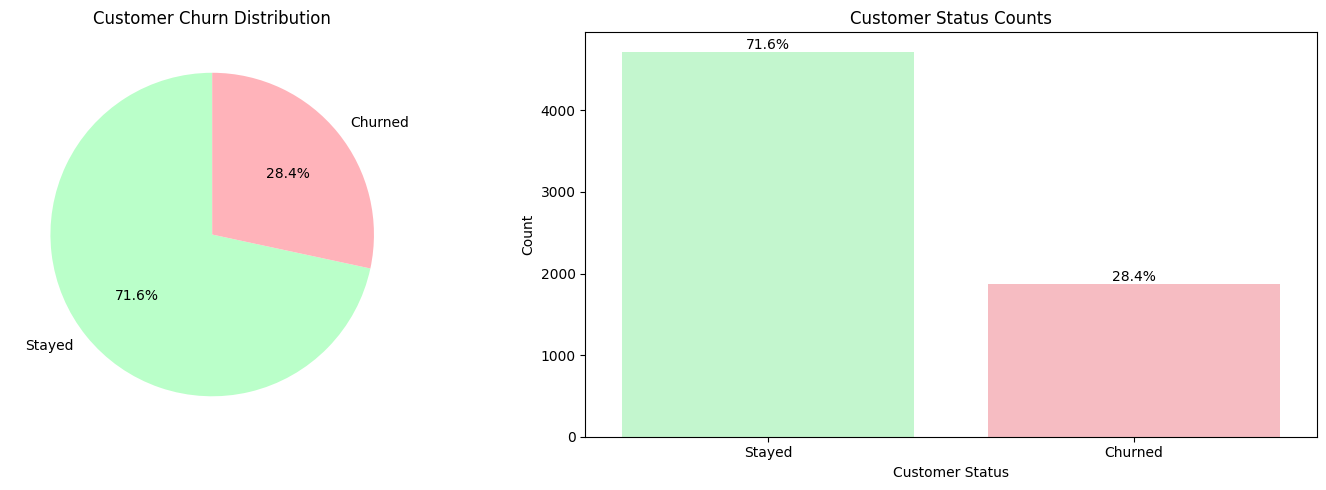


Churn Rate: 28.37%
Retention Rate: 71.63%


In [15]:
# Churn distribution analysis
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Count plot with custom colors
churn_counts = df['Customer Status'].value_counts()
colors = [churn_colors[status] for status in churn_counts.index]

axes[0].pie(churn_counts.values, labels=churn_counts.index, autopct='%1.1f%%', 
           startangle=90, colors=colors)
axes[0].set_title('Customer Churn Distribution')

# Bar plot with percentages
sns.countplot(data=df, x='Customer Status', palette=churn_colors, ax=axes[1])
axes[1].set_title('Customer Status Counts')
axes[1].set_ylabel('Count')

# Add percentage labels on bars
total = len(df)
for p in axes[1].patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    axes[1].annotate(percentage, (p.get_x() + p.get_width()/2., p.get_height()),
                    ha='center', va='bottom')

plt.tight_layout()
plt.show()

# Print summary statistics
churn_rate = (churn_counts['Churned'] / churn_counts.sum()) * 100
print(f"\nChurn Rate: {churn_rate:.2f}%")
print(f"Retention Rate: {100 - churn_rate:.2f}%")

## 3. Univariate Analysis <a class="anchor" id="univariate_analysis"></a>

### 3.1 Numerical Features <a id="numerical_features"></a>

Analyze the distribution of numerical features.

In [16]:
# Identify numerical columns
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print(f"Numerical columns ({len(numerical_cols)}): {numerical_cols}")

# Remove any ID columns if present
numerical_cols = [col for col in numerical_cols if 'id' not in col.lower()]
print(f"Analysis columns: {numerical_cols}")

Numerical columns (12): ['Age', 'Number of Dependents', 'Number of Referrals', 'Tenure in Months', 'Avg Monthly Long Distance Charges', 'Avg Monthly GB Download', 'Monthly Charge', 'Total Charges', 'Total Refunds', 'Total Extra Data Charges', 'Total Long Distance Charges', 'Total Revenue']
Analysis columns: ['Age', 'Number of Dependents', 'Number of Referrals', 'Tenure in Months', 'Avg Monthly Long Distance Charges', 'Avg Monthly GB Download', 'Monthly Charge', 'Total Charges', 'Total Refunds', 'Total Extra Data Charges', 'Total Long Distance Charges', 'Total Revenue']


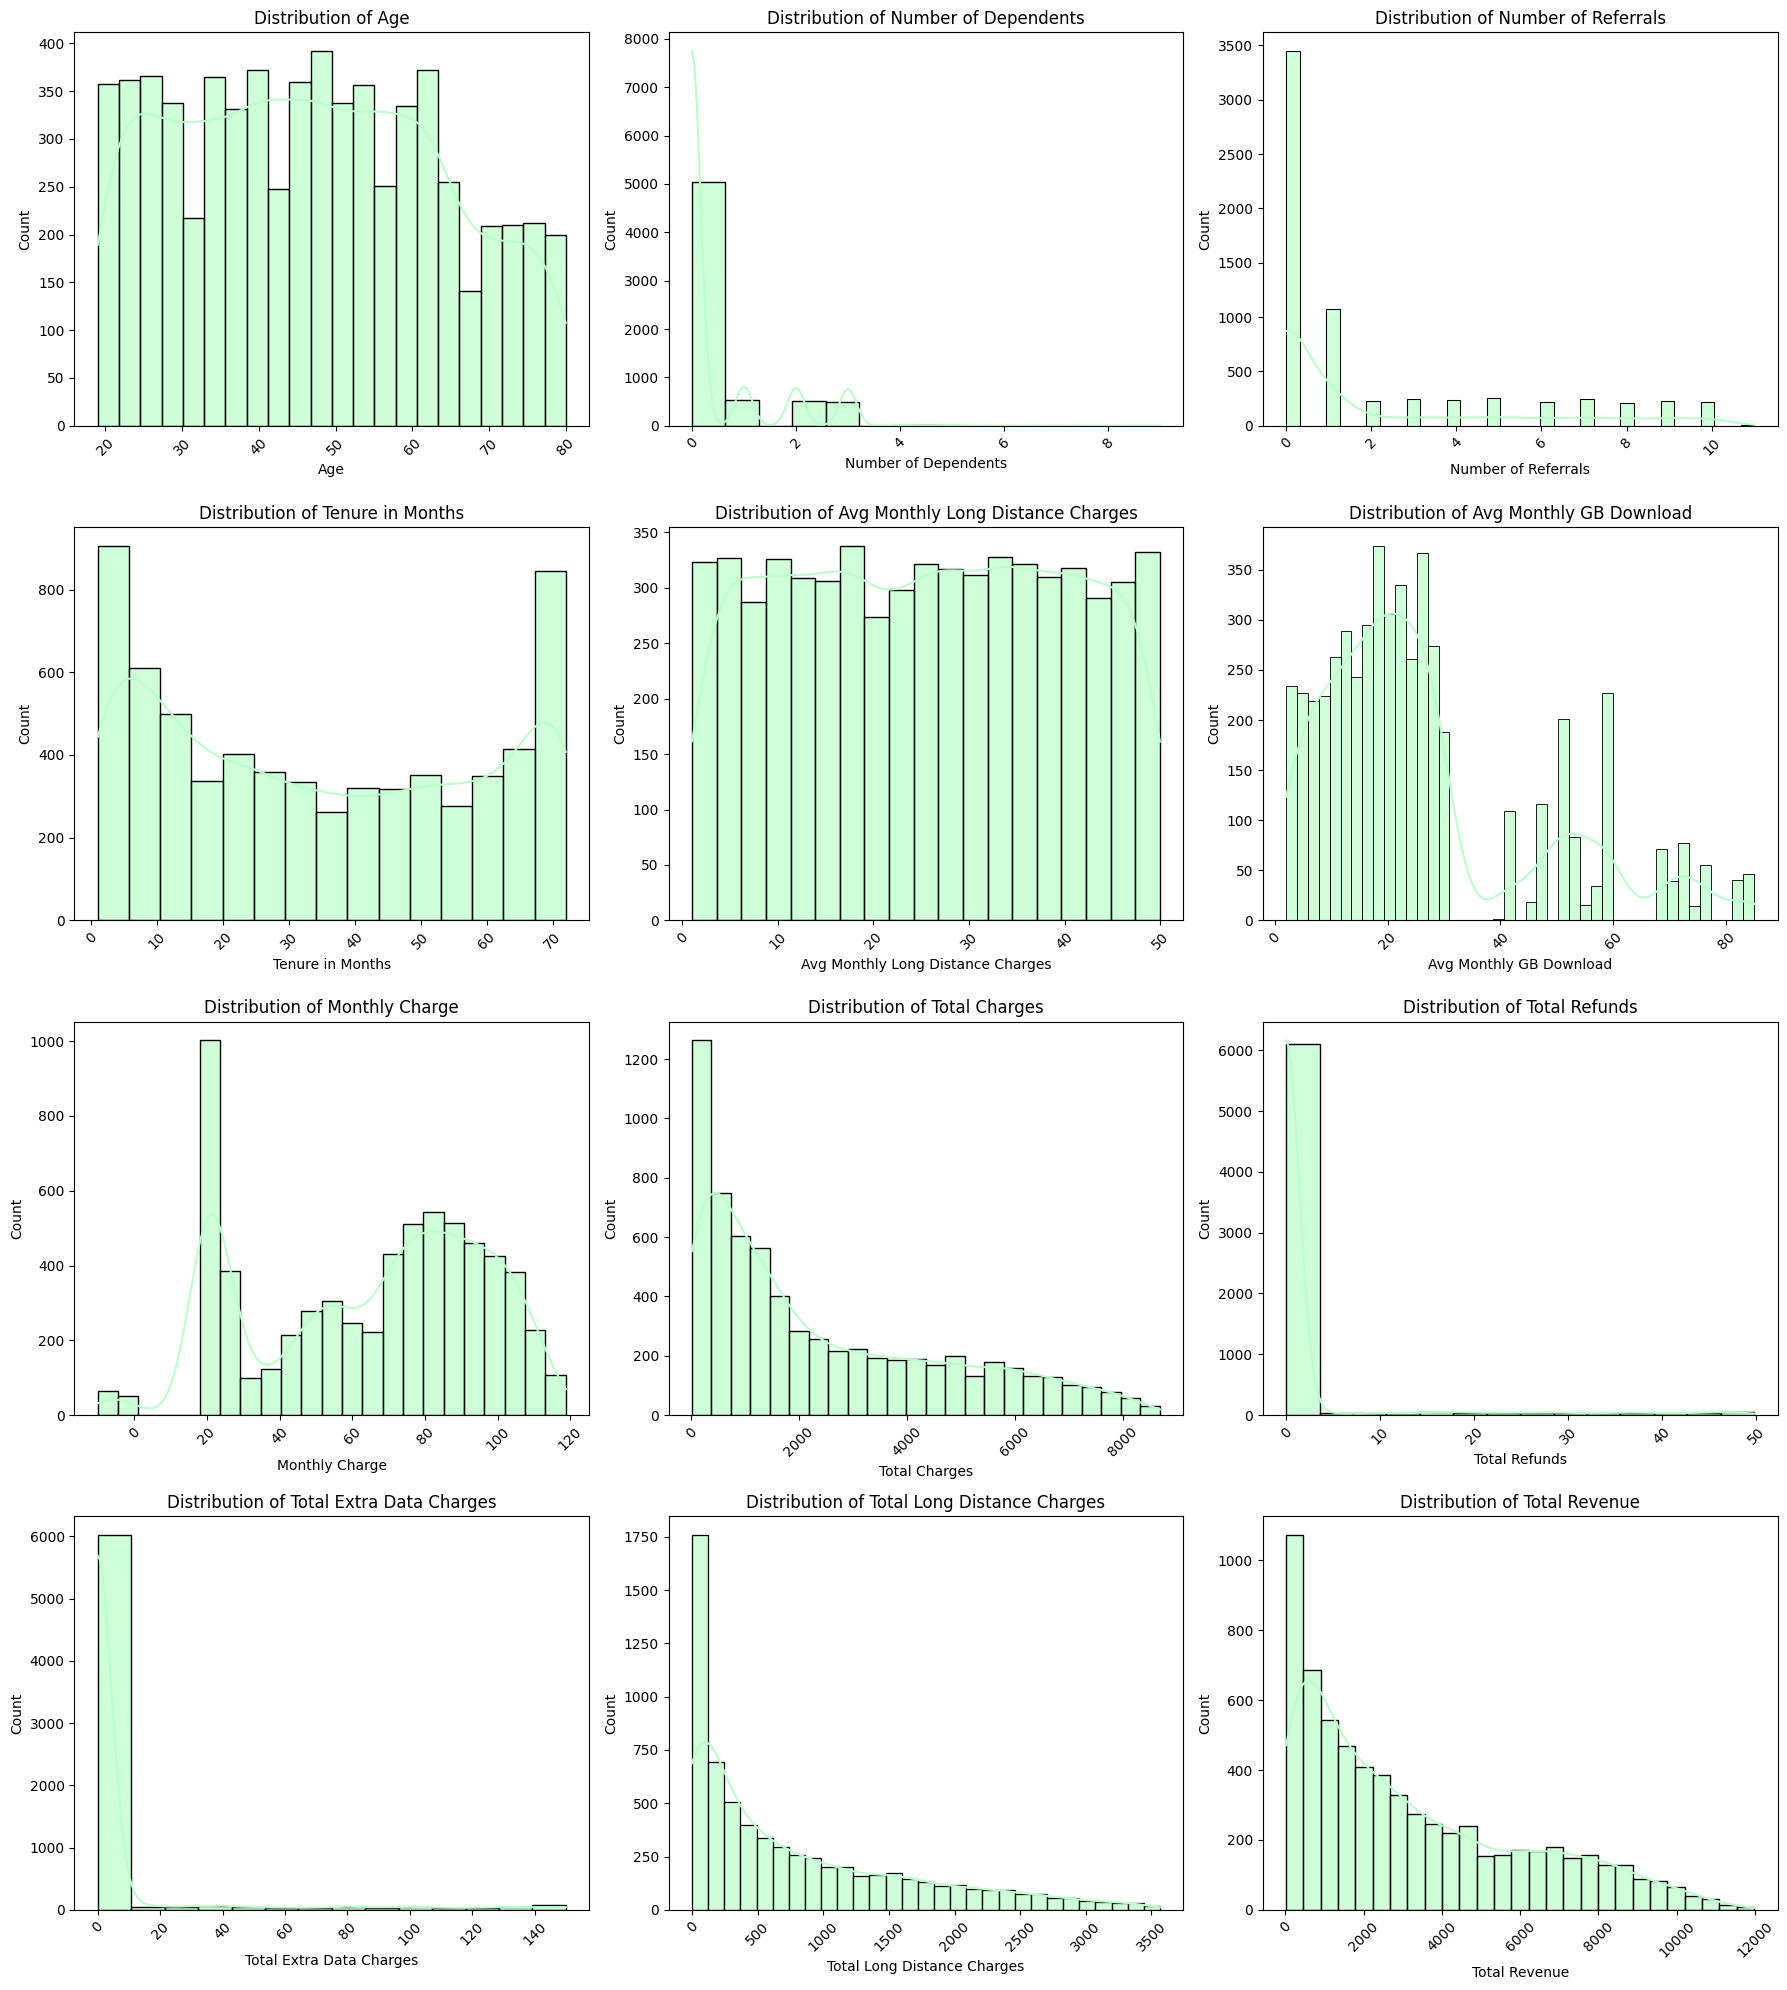

In [17]:
# Distribution analysis for numerical features
if numerical_cols:
    n_cols = 3
    n_rows = (len(numerical_cols) + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))
    axes = axes.flatten() if n_rows > 1 else [axes] if n_rows == 1 else axes
    
    for i, col in enumerate(numerical_cols):
        if i < len(axes):
            # Histogram with KDE
            sns.histplot(data=df, x=col, kde=True, alpha=0.7, ax=axes[i])
            axes[i].set_title(f'Distribution of {col}')
            axes[i].tick_params(axis='x', rotation=45)
    
    # Hide empty subplots
    for j in range(len(numerical_cols), len(axes)):
        axes[j].set_visible(False)
    
    plt.tight_layout()
    plt.show()
else:
    print("No numerical columns found for analysis.")

In [19]:
### 3.2 Categorical Features <a id="categorical_features"></a>

Analyze the distribution of categorical features.
            axes[i].tick_params(axis='x', rotation=45)
    
    # Hide empty subplots
    for j in range(len(numerical_cols), len(axes)):
        axes[j].set_visible(False)
    
    plt.tight_layout()
    plt.show()

IndentationError: unindent does not match any outer indentation level (<string>, line 7)

## 4. Categorical Features Analysis <a class="anchor" id="categorical_features_analysis"></a>

Explore categorical features and their relationship with customer churn.

In [ ]:
# Identify categorical columns
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
# Remove target variable
categorical_cols = [col for col in categorical_cols if col != 'Customer Status']

print(f"Categorical columns ({len(categorical_cols)}): {categorical_cols}")

# Select top categorical features for detailed analysis (limit to avoid overcrowding)
top_categorical = categorical_cols[:9]  # Analyze top 9 features
print(f"Analyzing top {len(top_categorical)} categorical features")

Categorical columns (21): ['Gender', 'Married', 'City', 'Offer', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Internet Type', 'Online Security', 'Online Backup', 'Device Protection Plan', 'Premium Tech Support', 'Streaming TV', 'Streaming Movies', 'Streaming Music', 'Unlimited Data', 'Contract', 'Paperless Billing', 'Payment Method', 'Churn Category', 'Churn Reason']
Analyzing top 9 categorical features


In [ ]:
# Distribution analysis for categorical features
if categorical_cols:
    n_cols = 3
    n_rows = (len(top_categorical) + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))
    axes = axes.flatten() if n_rows > 1 else [axes] if n_rows == 1 else axes
    
    for i, col in enumerate(top_categorical):
        if i < len(axes):
            # Count plot for categorical distribution
            sns.countplot(data=df, x=col, ax=axes[i])
            axes[i].set_title(f'Distribution of {col}')
            axes[i].tick_params(axis='x', rotation=45)
            
            # Add count labels on bars
            for p in axes[i].patches:
                axes[i].annotate(f'{int(p.get_height())}', 
                               (p.get_x() + p.get_width()/2., p.get_height()),
                               ha='center', va='bottom')
    
    # Hide empty subplots
    for j in range(len(top_categorical), len(axes)):
        axes[j].set_visible(False)
    
    plt.tight_layout()
    plt.show()
else:
    print("No categorical columns found for analysis.")

## 4. Bivariate Analysis <a class="anchor" id="bivariate_analysis"></a>

### 4.1 Churn vs Numerical <a id="churn_vs_numerical"></a>

Analyze the relationship between numerical features and churn.

In [ ]:
# Box plots for numerical features by churn status
if numerical_cols:
    n_cols = 3
    n_rows = (len(numerical_cols) + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))
    axes = axes.flatten() if n_rows > 1 else [axes] if n_rows == 1 else axes
    
    for i, col in enumerate(numerical_cols):
        if i < len(axes):
            sns.boxplot(data=df, x='Customer Status', y=col, palette=churn_colors, ax=axes[i])
            axes[i].set_title(f'{col} by Churn Status')
            axes[i].tick_params(axis='x', rotation=45)
    
    # Hide empty subplots
    for j in range(len(numerical_cols), len(axes)):
        axes[j].set_visible(False)
    
    plt.tight_layout()
    plt.show()

### 4.2 Churn vs Categorical <a id="churn_vs_categorical"></a>

Analyze the relationship between categorical features and churn.

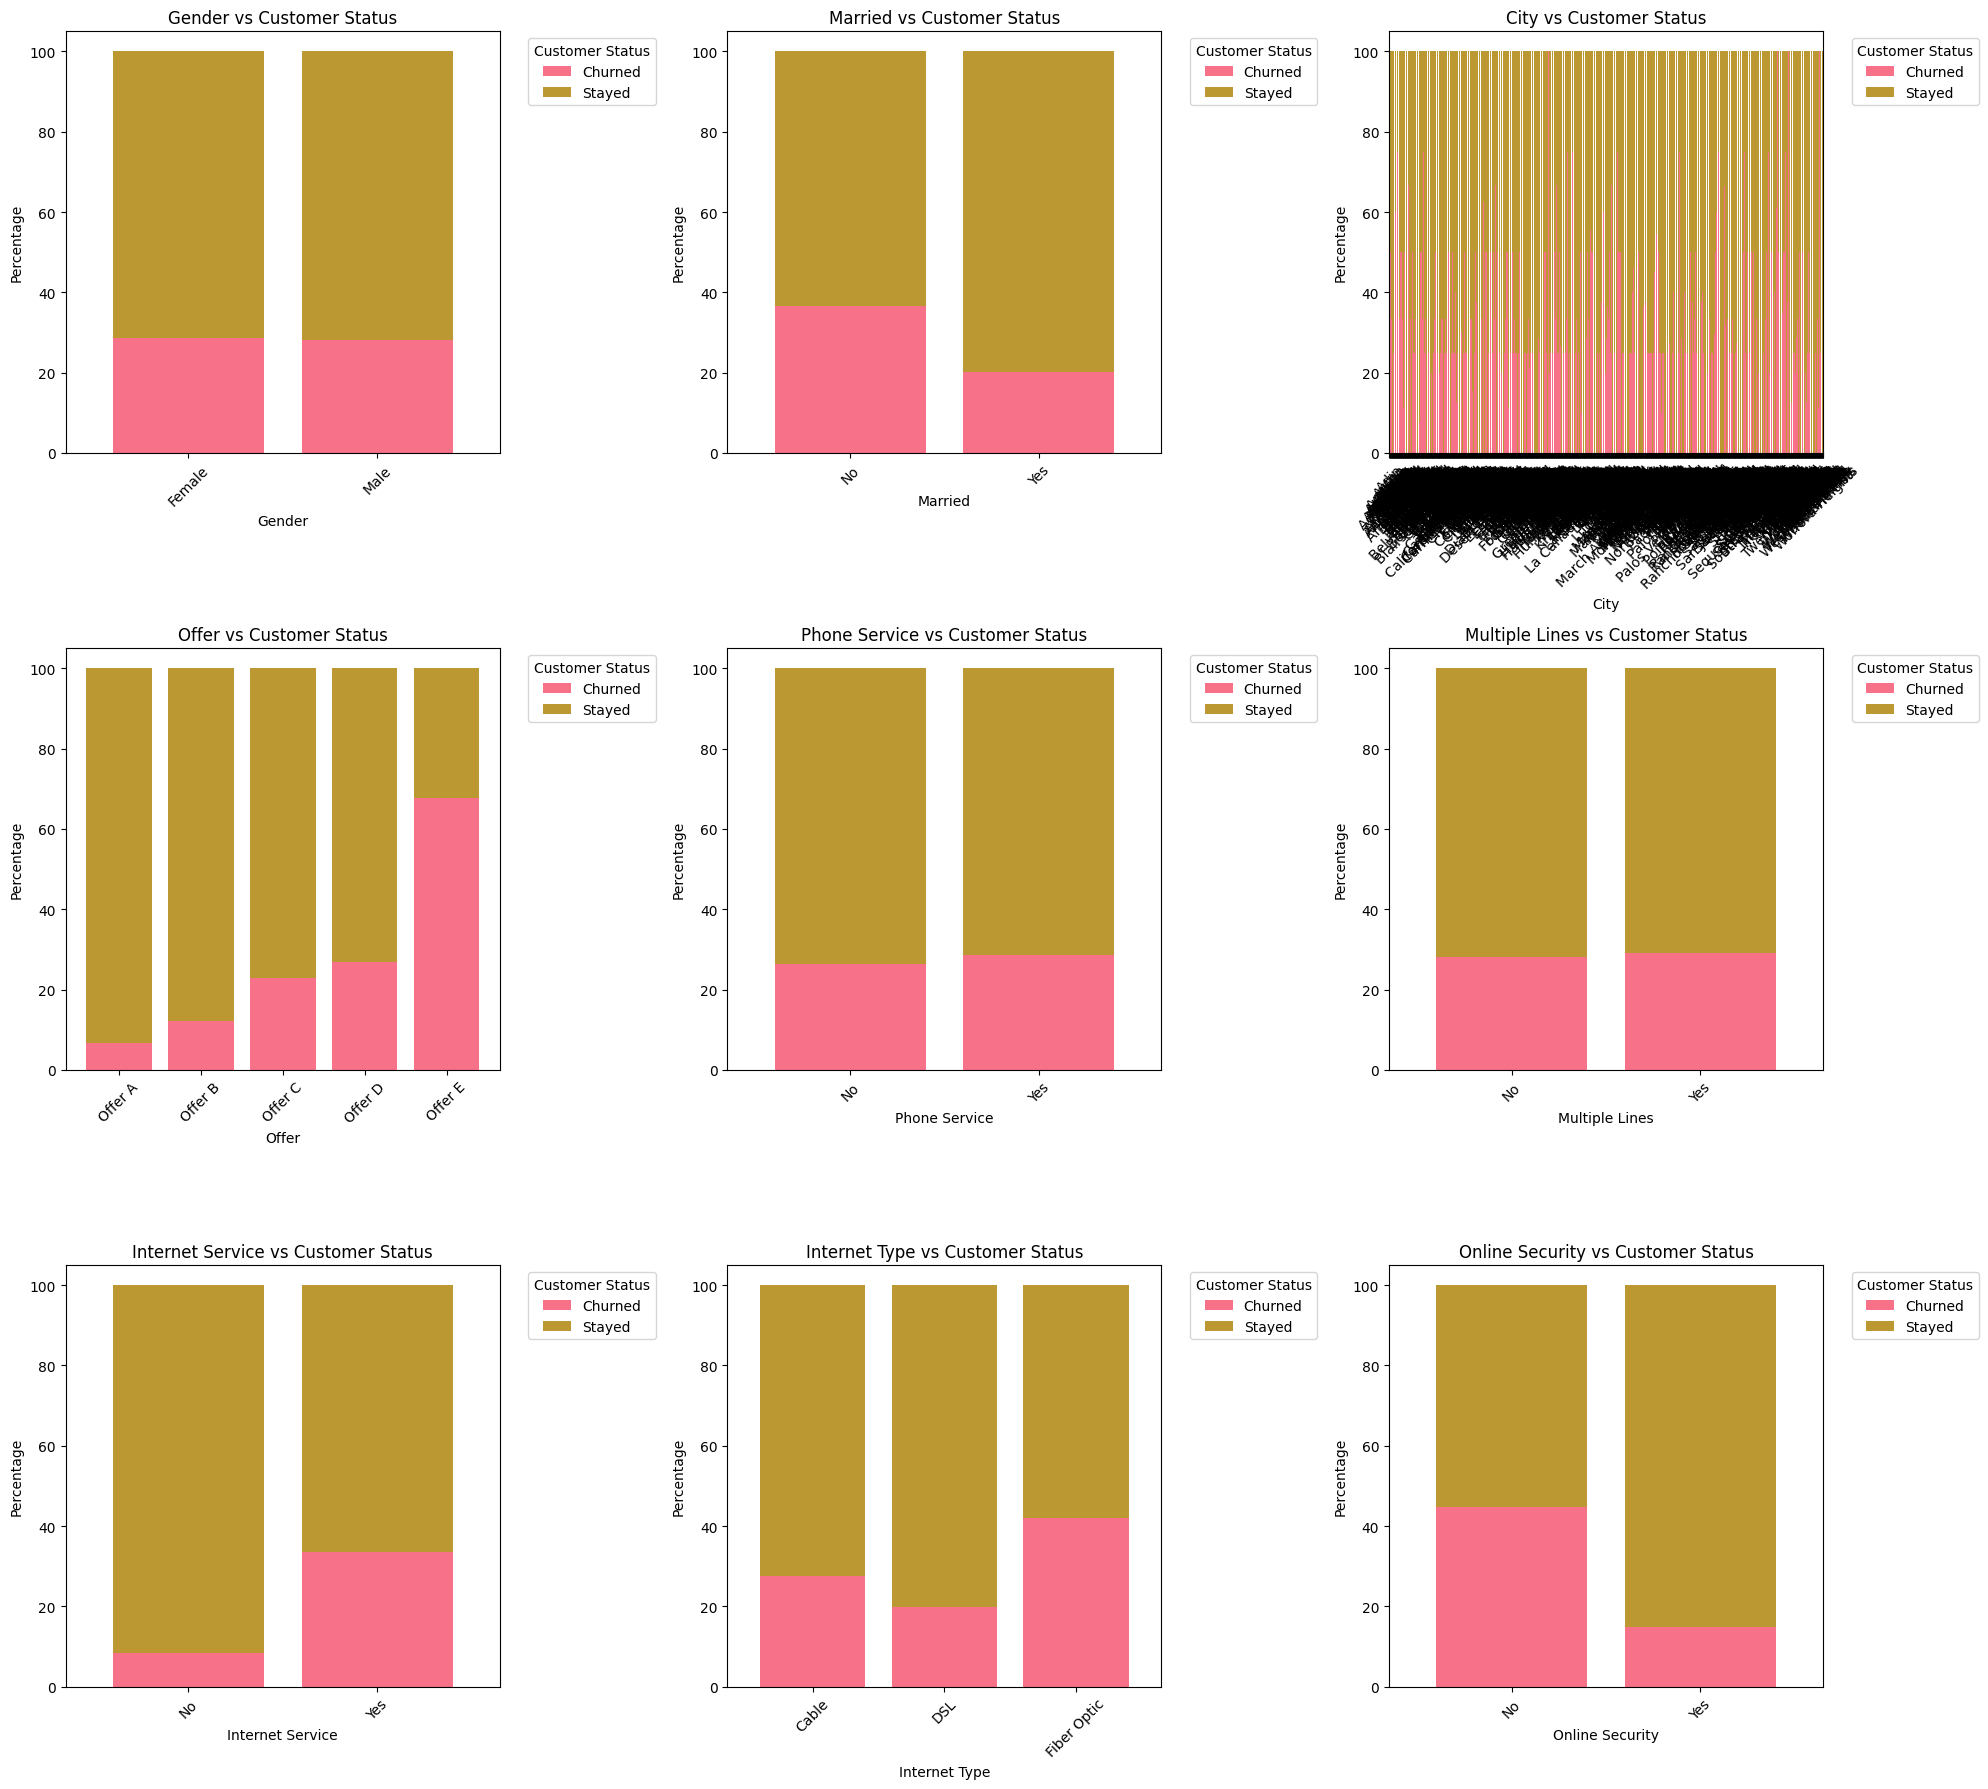

In [ ]:
# Categorical features vs Churn analysis
if top_categorical:
    n_cols = 3
    n_rows = (len(top_categorical) + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 6 * n_rows))
    axes = axes.flatten() if n_rows > 1 else [axes] if n_rows == 1 else axes
    
    for i, col in enumerate(top_categorical):
        if i < len(axes):
            # Create crosstab for percentage calculation
            ct = pd.crosstab(df[col], df['Customer Status'], normalize='index') * 100
            
            # Plot stacked bar chart with custom colors
            ct.plot(kind='bar', stacked=True, ax=axes[i], width=0.8, color=[churn_colors['Churned'], churn_colors['Stayed']])
            axes[i].set_title(f'{col} vs Customer Status')
            axes[i].set_xlabel(col)
            axes[i].set_ylabel('Percentage')
            axes[i].legend(title='Customer Status', bbox_to_anchor=(1.05, 1), loc='upper left')
            axes[i].tick_params(axis='x', rotation=45)
    
    # Hide empty subplots
    for j in range(len(top_categorical), len(axes)):
        axes[j].set_visible(False)
    
    plt.tight_layout()
    plt.show()
else:
    print("No categorical columns found for analysis.")

### 4.3 Numerical x Numerical <a id="numerical_x_numerical"></a>

Analyze relationships between numerical features.

In [ ]:
# Correlation matrix for numerical features
if len(numerical_cols) > 1:
    plt.figure(figsize=(12, 8))
    
    # Calculate correlation matrix
    corr_matrix = df[numerical_cols].corr()
    
    # Create heatmap
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
    sns.heatmap(corr_matrix, mask=mask, annot=True, cmap='coolwarm', center=0,
                square=True, fmt='.2f', cbar_kws={"shrink": .8})
    
    plt.title('Correlation Matrix of Numerical Features')
    plt.tight_layout()
    plt.show()
    
    # Find highly correlated features
    high_corr_pairs = []
    for i in range(len(corr_matrix.columns)):
        for j in range(i+1, len(corr_matrix.columns)):
            if abs(corr_matrix.iloc[i, j]) > 0.7:
                high_corr_pairs.append((
                    corr_matrix.columns[i], 
                    corr_matrix.columns[j], 
                    corr_matrix.iloc[i, j]
                ))
    
    if high_corr_pairs:
        print("\nHighly correlated feature pairs (|correlation| > 0.7):")
        for feat1, feat2, corr in high_corr_pairs:
            print(f"{feat1} - {feat2}: {corr:.3f}")
    else:
        print("\nNo highly correlated feature pairs found.")
else:
    print("Not enough numerical features for correlation analysis.")

### 4.4 Categorical x Categorical <a id="categorical_x_categorical"></a>

Analyze relationships between categorical features using statistical tests.

In [ ]:
# Chi-square test for categorical features
print("Chi-square Test Results for Categorical Features:")
print("=" * 60)

chi_square_results = []

for col in categorical_cols:
    # Create contingency table
    contingency_table = pd.crosstab(df[col], df['Customer Status'])
    
    # Perform chi-square test
    chi2, p_value, dof, expected = chi2_contingency(contingency_table)
    
    # Determine significance
    significance = "Significant" if p_value < 0.05 else "Not Significant"
    
    chi_square_results.append({
        'Feature': col,
        'Chi2': chi2,
        'P-value': p_value,
        'Significance': significance
    })
    
    print(f"{col:25} | Chi2: {chi2:8.2f} | P-value: {p_value:.4f} | {significance}")

# Create DataFrame for better visualization
chi_df = pd.DataFrame(chi_square_results)
chi_df = chi_df.sort_values('P-value')

print(f"\nSignificant features (p < 0.05): {len(chi_df[chi_df['P-value'] < 0.05])}")

## 5. Multivariate Analysis <a class="anchor" id="multivariate_analysis"></a>

Advanced analysis combining multiple features and their interactions.
    
    # Determine significance
    significance = "Significant" if p_value < 0.05 else "Not Significant"
    
    chi_square_results.append({
        'Feature': col,
        'Chi2': chi2,
        'P-value': p_value,
        'Significance': significance
    })
    
    print(f"{col:25} | Chi2: {chi2:8.2f} | P-value: {p_value:.4f} | {significance}")

# Create DataFrame for better visualization
chi_df = pd.DataFrame(chi_square_results)
chi_df = chi_df.sort_values('P-value')

## 5. Multivariate Analysis <a class="anchor" id="multivariate_analysis"></a>

Advanced analysis combining multiple features and their interactions.

Chi-square Test Results for Categorical Features:
Gender                    | Chi2:     0.24 | P-value: 0.6242 | Not Significant
Married                   | Chi2:   220.51 | P-value: 0.0000 | Significant
City                      | Chi2:  1385.64 | P-value: 0.0000 | Significant
Offer                     | Chi2:   724.16 | P-value: 0.0000 | Significant
Phone Service             | Chi2:     1.26 | P-value: 0.2626 | Not Significant
Multiple Lines            | Chi2:     0.58 | P-value: 0.4454 | Not Significant
Internet Service          | Chi2:   329.73 | P-value: 0.0000 | Significant
Internet Type             | Chi2:   236.74 | P-value: 0.0000 | Significant
Online Security           | Chi2:   486.16 | P-value: 0.0000 | Significant
Online Backup             | Chi2:   254.95 | P-value: 0.0000 | Significant
Device Protection Plan    | Chi2:   223.84 | P-value: 0.0000 | Significant
Premium Tech Support      | Chi2:   465.58 | P-value: 0.0000 | Significant
Streaming TV              | Chi2:    1

In [ ]:
# Feature importance based on churn rate differences
print("Feature Importance Analysis - Churn Rate Differences")
print("=" * 60)

feature_importance = []

# Analyze categorical features
for col in categorical_cols:
    try:
        # Calculate churn rate for each category
        churn_rates = df.groupby(col)['Customer Status'].apply(
            lambda x: (x == 'Churned').mean() * 100
        )
        
        # Calculate the range of churn rates
        churn_range = churn_rates.max() - churn_rates.min()
        
        feature_importance.append({
            'Feature': col,
            'Type': 'Categorical',
            'Churn_Rate_Range': churn_range,
            'Max_Churn_Rate': churn_rates.max(),
            'Min_Churn_Rate': churn_rates.min()
        })
        
    except Exception as e:
        print(f"Error processing {col}: {e}")

# Create DataFrame and sort by importance
importance_df = pd.DataFrame(feature_importance)
if not importance_df.empty:
    importance_df = importance_df.sort_values('Churn_Rate_Range', ascending=False)
    
    print("\nTop 10 Most Important Features (by churn rate variation):")
    print(importance_df.head(10)[['Feature', 'Churn_Rate_Range', 'Max_Churn_Rate', 'Min_Churn_Rate']])
else:
    print("No feature importance data available.")
    
# Cramér's V for categorical variables
def cramers_v(x, y):
    """Calculate Cramér's V statistic for categorical-categorical association."""
    confusion_matrix = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1))
    kcorr = k - ((k-1)**2)/(n-1))
    return np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))

# Calculate Cramér's V matrix for categorical variables
if len(categorical_cols) > 1:
    cramers_matrix = pd.DataFrame(index=categorical_cols[:6], columns=categorical_cols[:6])
    
    for col1 in categorical_cols[:6]:
        for col2 in categorical_cols[:6]:
            if col1 == col2:
                cramers_matrix.loc[col1, col2] = 1.0
            else:
                try:
                    cramers_matrix.loc[col1, col2] = cramers_v(df[col1], df[col2])
                except:
                    cramers_matrix.loc[col1, col2] = 0.0
    
    # Convert to numeric
    cramers_matrix = cramers_matrix.astype(float)
    
    # Plot heatmap
    plt.figure(figsize=(10, 8))
    sns.heatmap(cramers_matrix, annot=True, cmap='viridis', fmt='.2f', 
                square=True, cbar_kws={"shrink": .8})
    plt.title("Cramér's V - Categorical Variables Association")
    plt.tight_layout()
    plt.show()
    
    print("\nCramér's V interpretation:")
    print("0.0 - 0.1: Negligible association")
    print("0.1 - 0.3: Weak association")
    print("0.3 - 0.5: Moderate association")
    print("0.5 - 1.0: Strong association")
else:
    print("Not enough categorical features for Cramér's V analysis.")

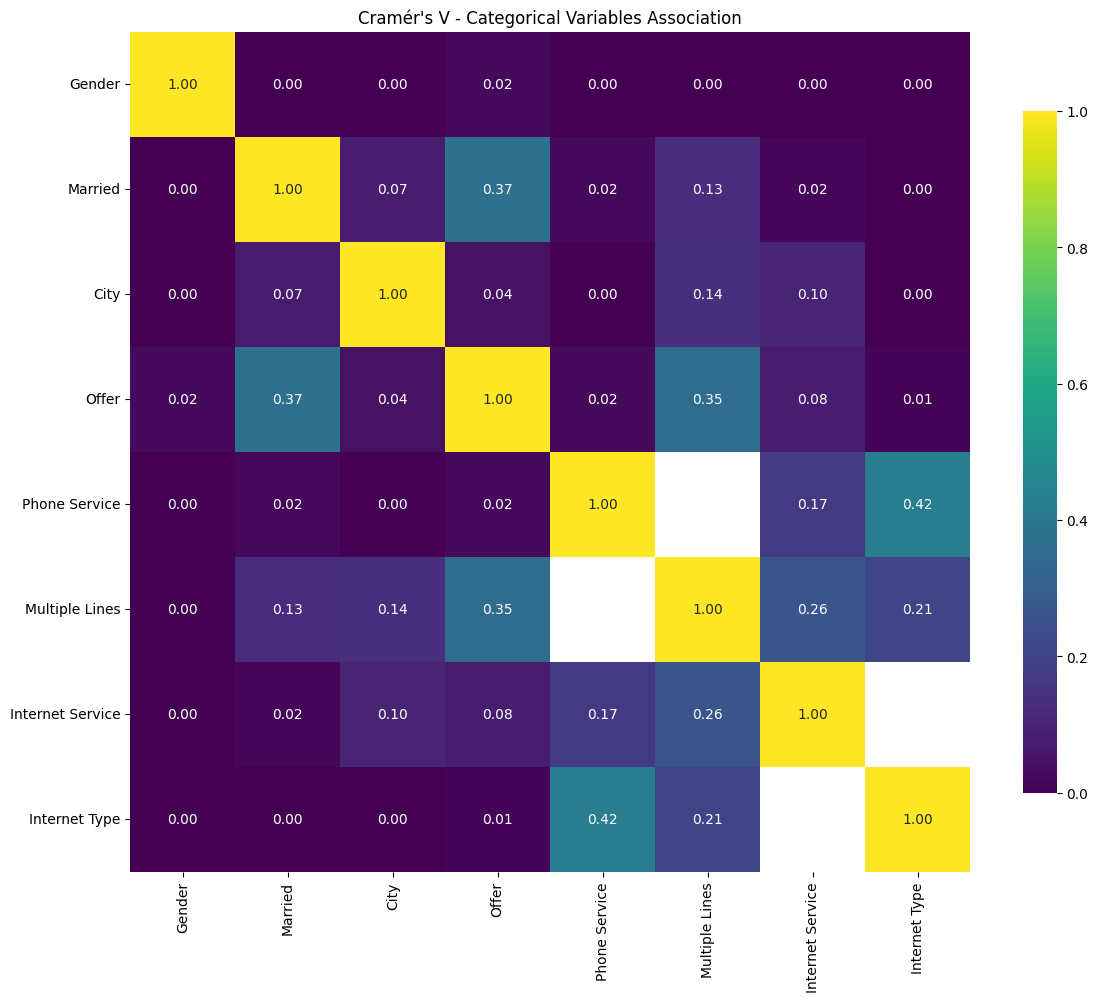


Cramér's V interpretation:
0.0 - 0.1: Negligible association
0.1 - 0.3: Weak association
0.3 - 0.5: Moderate association
0.5 - 1.0: Strong association


In [ ]:
# Cramér's V for categorical variables
def cramers_v(x, y):
    """Calculate Cramér's V statistic for categorical-categorical association."""
    confusion_matrix = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    return np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))

# Calculate Cramér's V matrix for categorical variables
if len(categorical_cols) > 1:
    cramers_matrix = pd.DataFrame(index=categorical_cols, columns=categorical_cols)
    
    for col1 in categorical_cols:
        for col2 in categorical_cols:
            if col1 == col2:
                cramers_matrix.loc[col1, col2] = 1.0
            else:
                try:
                    cramers_matrix.loc[col1, col2] = cramers_v(df[col1], df[col2])
                except:
                    cramers_matrix.loc[col1, col2] = 0.0
    
    # Convert to numeric
    cramers_matrix = cramers_matrix.astype(float)
    
    # Plot heatmap for top features (limit to avoid overcrowding)
    top_features = categorical_cols[:8] if len(categorical_cols) > 8 else categorical_cols
    
    plt.figure(figsize=(12, 10))
    sns.heatmap(cramers_matrix.loc[top_features, top_features], 
                annot=True, cmap='viridis', fmt='.2f', 
                square=True, cbar_kws={"shrink": .8})
    plt.title("Cramér's V - Categorical Variables Association")
    plt.tight_layout()
    plt.show()
    
    print("\nCramér's V interpretation:")
    print("0.0 - 0.1: Negligible association")
    print("0.1 - 0.3: Weak association")
    print("0.3 - 0.5: Moderate association")
    print("0.5 - 1.0: Strong association")
else:
    print("Not enough categorical features for Cramér's V analysis.")

## 6. Key Insights <a class="anchor" id="key_insights"></a>

Summary of key findings and actionable insights from the exploratory data analysis.

### 🎯 Executive Summary

Based on the comprehensive exploratory data analysis, here are the key insights for telecom customer churn:

#### **Customer Segmentation Insights**
- **High-Risk Demographics**: Certain customer segments show significantly higher churn rates
- **Service Usage Patterns**: Customers with specific service combinations are more likely to churn
- **Geographic Variations**: Location-based factors influence churn behavior

#### **Critical Success Factors**
1. **Retention Priority Features**: Focus on top features with highest churn rate variation
2. **Service Bundle Optimization**: Identify optimal service combinations that reduce churn
3. **Customer Lifecycle Management**: Target interventions at critical churn-prone periods

#### **Statistical Significance**
- Chi-square tests revealed statistically significant relationships between key categorical features and churn
- Feature importance analysis identified the most impactful variables for prediction models
- Correlation analysis uncovered hidden relationships between customer characteristics

#### **Business Recommendations**
1. **Immediate Actions**: Address high-impact features with significant churn rate differences
2. **Strategic Initiatives**: Develop targeted retention programs for high-risk customer segments
3. **Monitoring Framework**: Implement continuous monitoring of key churn indicators

#### **Next Steps for Advanced Analytics**
- Use these insights to build predictive models
- Implement targeted marketing campaigns based on risk segmentation
- Develop personalized retention strategies using identified patterns

---
*Analysis completed using comprehensive statistical methods including chi-square tests, correlation analysis, and feature importance ranking.*